# Neural Boltzmann Machine 2

### MNIST to FashionMNIST

We will now use the FashionMNIST dataset, which will have images of 10 diffeerent classes of clothing & accesory.

However, now we want to learn the grayscale values of the images as well, since clothing images require more detail. We therefore modify our original Bernoulli visible-Bernolli hidden neural boltzmann machine to Guassian visible-Bernoulli hidden version. Hence our energy function now will be expressed as following:

$$
E(\mathbf v,\mathbf h | x)
= \frac{1}{2} (\mathbf v-\mathbf a_{\phi}(x))^T(\mathbf v-\mathbf a_{\phi}(x)) -\mathbf b_{\chi}(x)^T\mathbf h-\mathbf v^T\mathbf W_{\psi}(x)\mathbf h
$$

Moreover, since the visible units now will be continuous variables and we assumed quadratic contribution to energy, their conditional distribution will be gaussian.

**Proof:**
Our RBM energy in summation form can be written as following ($a$, $b$, $W$ constant neural network outputs):

$$
E(\mathbf v,\mathbf h)
=
\frac12\sum_i(v_i-a_i)^2
-\sum_\mu b_\mu h_\mu
-\sum_{i\mu}v_iW_{i\mu}h_\mu.
$$

Conditioning on the hidden units, keep only terms depending on $v_i$:

$$
E_i(v_i|\mathbf h)
=
\frac12(v_i-a_i)^2
-v_i\sum_\mu W_{i\mu}h_\mu.
$$

Define

$$
F_i=\sum_\mu W_{i\mu}h_\mu.
$$

Then

$$
E_i
=
\frac12(v_i-a_i)^2-v_iF_i.
$$

Expand:

$$
E_i
=
\frac12v_i^2-a_iv_i+\frac12a_i^2-v_iF_i
$$

$$
=
\frac12v_i^2-(a_i+F_i)v_i+\frac12a_i^2.
$$

Now complete the square:

$$
\frac12v_i^2-(a_i+F_i)v_i
=
\frac12\left[v_i-(a_i+F_i)\right]^2
-\frac12(a_i+F_i)^2.
$$

Therefore,

$$
E_i(v_i|\mathbf h)
=
\frac12\left[v_i-(a_i+F_i)\right]^2+\text{const}.
$$

Hence,

$$
P(v_i|\mathbf h)
\propto
\exp\left[
-\frac12\left(v_i-a_i-\sum_\mu W_{i\mu}h_\mu\right)^2
\right].
$$

So,

$$
\boxed{
P(v_i|\mathbf h)
=
\mathcal N\left(
a_i+\sum_\mu W_{i\mu}h_\mu,\,
1
\right).
}
$$


torch.Size([60000, 784])


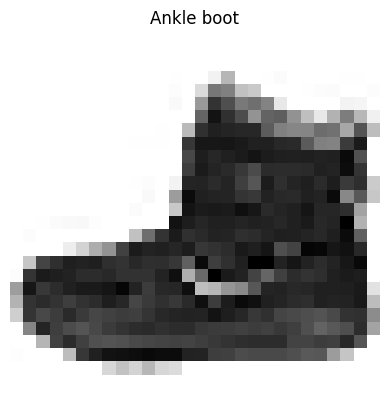

In [12]:
import torch
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")


def preprocess(data):
    # Preprocess image for better training
    mean = data.mean()
    std = data.std()
    data = (data - mean) / std
    return data, mean, std


def recover(data, mean, std):
    # Recover original image from the preprocessed image
    return (std*data) + mean


train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
)

# Normalize grayscale pixels to [0, 1] and flatten
X_train = train_data.data.float().reshape(-1, 784) / 255.0
X_train, mean, std = preprocess(X_train)
y_train = train_data.targets # y_train[0]: the first image has label 9
class_names = train_data.classes # class_names[9]: # "Ankle boot"

print(X_train.shape)  # torch.Size([60000, 784])

# Plot an example
plt.imshow(1 - recover(X_train[0].reshape(28, 28), mean, std), cmap="gray", vmin=0, vmax=1)
plt.title(class_names[y_train[0]])
plt.axis("off")
plt.show()

Total T-shirt/top images: 6000
Total Trouser images: 6000
Total Pullover images: 6000
Total Dress images: 6000
Total Coat images: 6000
Total Sandal images: 6000
Total Shirt images: 6000
Total Sneaker images: 6000
Total Bag images: 6000
Total Ankle boot images: 6000


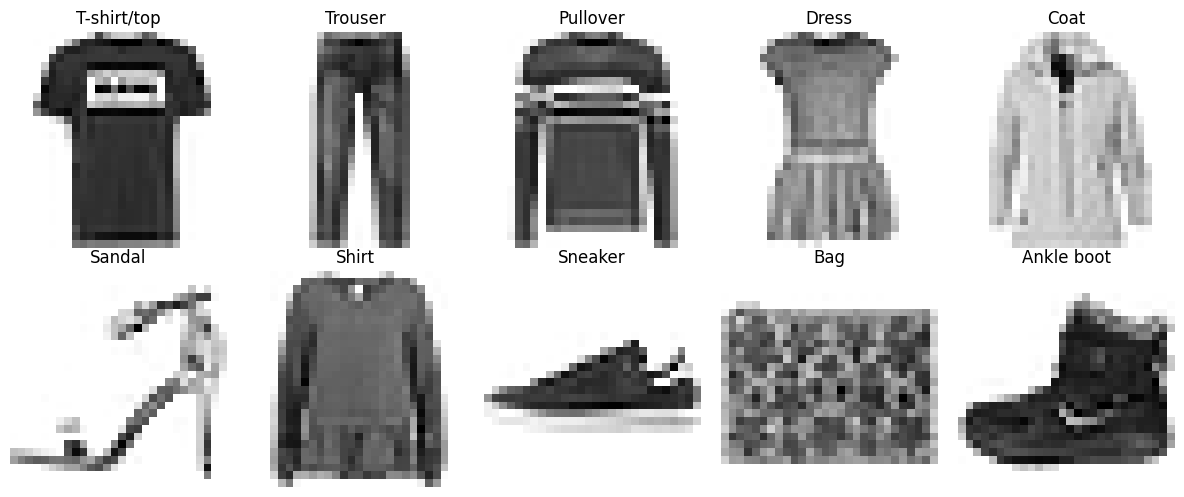

In [13]:
# Each group now represents a clothing class.
clothes = {
    label: X_train[y_train == label]
    for label in range(10)
}

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for label, ax in enumerate(axes.flat):
    print(f"Total {class_names[label]} images: {len(clothes[label])}")
    ax.imshow(
        1 - recover(clothes[label][0].reshape(28, 28), mean, std),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [14]:
def sigmoid(x):
    return torch.sigmoid(x)

def hidden_probabilities(v, W, b_h):
    """P(h=1 | v): accepts [N] or [batch, N], returns [M] or [batch, M]."""
    return sigmoid(v @ W + b_h)

def visible_means(h, W, a):
    """Mean value for visible variables: accepts [N] or [batch, N], returns [M] or [batch, M]."""
    return h @ W.T + a

@torch.no_grad()
def Block_Gibbs_sampling(v, W, b_v, b_h, n):
    """Perform n Gibbs steps for one visible state or a batch of states."""
    for _ in range(n):
        # Sample hidden states conditioned on visible states.
        h = torch.bernoulli(hidden_probabilities(v, W, b_h))
        # Sample visible states conditioned on hidden states.
        mean_v = visible_means(h, W, b_v)
        v = mean_v + 0.1*torch.randn_like(mean_v)
    return v

@torch.no_grad()
def persistent_gibbs_sampling(v_set, W, b_v, b_h, n=20):
    """Advance persistent visible chains of shape [num_chains, N]."""
    samples = Block_Gibbs_sampling(v_set, W, b_v, b_h, n)
    # Draw hidden states conditioned on the final visible states.
    samples_h = torch.bernoulli(hidden_probabilities(samples, W, b_h))
    return samples, samples_h

def vh_data(v_set, W, b_h):
    """Data expectation <v_i h_mu>: [batch, N] -> [N, M]."""
    return (v_set.T @ hidden_probabilities(v_set, W, b_h)) / len(v_set)

def v_data(v_set, W, b_h):
    """Data expectation <v_i>: [batch, N] -> [N]."""
    return v_set.mean(dim=0)

def h_data(v_set, W, b_h):
    """Data expectation <h_mu>: [batch, N] -> [M]."""
    return hidden_probabilities(v_set, W, b_h).mean(dim=0)

def vh_model(samples, samples_h):
    """Model expectation <v_i h_mu>, averaged over persistent chains."""
    return (samples.T @ samples_h) / len(samples)

def v_model(samples):
    return samples.mean(dim=0)

def h_model(samples_h):
    return samples_h.mean(dim=0)

In [15]:
def make_net(output_dim):
    return nn.Sequential(
        nn.Linear(1, 32),
        nn.ReLU(),
        nn.Linear(32, output_dim),
    )


class NeuralRBM(nn.Module):
    def __init__(self, num_vis, num_hid):
        super().__init__()
        self.num_vis = num_vis
        self.num_hid = num_hid

        self.a_net = make_net(num_vis)
        self.b_net = make_net(num_hid)
        self.W_net = make_net(num_vis * num_hid)

    def forward(self, z):
        # z (digit labels): [batch_size, 1]
        a = self.a_net(z)
        b = self.b_net(z)
        W = self.W_net(z).reshape(-1, self.num_vis, self.num_hid)
        return a, b, W

In [16]:
N, M = 784, 128
batch_size = 256
num_epochs = 50
learning_rate = 1e-3

train_dataset = TensorDataset(X_train, y_train)
train_batches = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
)

# Initialize parameter generating model and optimizer
model = NeuralRBM(N, M).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# One persistent chain per digit
# Keep a batch dimension of size 1 for the existing helpers
# 64 persistent chains for each digit
samples = 0.1 * torch.randn(10, 64, N, device=device)

# Float inputs of shape [10, 1] for the parameter networks
label_inputs = torch.arange(10, device=device).float().unsqueeze(1)

history = []
model.train()
for epoch in range(num_epochs):
    total_errors = torch.zeros(3, device=device)
    num_examples = 0

    for v_batch, labels in train_batches:
        v_batch = v_batch.to(device)
        labels = labels.to(device)  # [batch_size]
        batch_n = len(v_batch)

        optimizer.zero_grad()

        # Generate RBM parameters for all ten digits
        a_all, b_all, W_all = model(label_inputs)
        loss = torch.zeros((), device=device)

        for digit in labels.unique().tolist():
            v_digit = v_batch[labels == digit]
            digit_n = len(v_digit)

            a = a_all[digit]
            b = b_all[digit]
            W = W_all[digit]

            # Estimate MLE gradients without differentiating
            with torch.no_grad():
                samples[digit], samples_h = persistent_gibbs_sampling(samples[digit], W, a, b, 100)
                err_W = vh_data(v_digit, W, b) - vh_model(samples[digit], samples_h)
                err_a = v_data(v_digit, W, b) - v_model(samples[digit])
                err_b = h_data(v_digit, W, b) - h_model(samples_h)

                total_errors += digit_n * torch.stack([
                    err_W.norm(), err_a.norm(), err_b.norm()
                ])

            # Surrogate loss: backpropagate the MLE gradients
            # Weight each digit by its frequency in this batch
            # MLE grad losses will be treated as constants and propagate through network
            loss -= (digit_n / batch_n) * (
                (W * err_W).sum()
                + (a * err_a).sum()
                + (b * err_b).sum()
            )

        loss.backward()
        optimizer.step()
        num_examples += batch_n

    mean_errors = (total_errors / num_examples).cpu().tolist()
    history.append(mean_errors)

    if epoch == 0 or epoch == num_epochs - 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch + 1:3d}/{num_epochs} | "
            f"W gradient norm: {mean_errors[0]:.4f} | "
            f"a gradient norm: {mean_errors[1]:.4f} | "
            f"b gradient norm: {mean_errors[2]:.4f}"
        )

Epoch   1/50 | W gradient norm: 287.3755 | a gradient norm: 33.2968 | b gradient norm: 4.1278
Epoch   6/50 | W gradient norm: 116.3264 | a gradient norm: 16.6155 | b gradient norm: 1.3163
Epoch  11/50 | W gradient norm: 115.6607 | a gradient norm: 16.5693 | b gradient norm: 1.3103
Epoch  16/50 | W gradient norm: 115.3951 | a gradient norm: 16.5743 | b gradient norm: 1.3691
Epoch  21/50 | W gradient norm: 87.3606 | a gradient norm: 12.3350 | b gradient norm: 1.1914
Epoch  26/50 | W gradient norm: 76.2347 | a gradient norm: 10.6806 | b gradient norm: 1.0177
Epoch  31/50 | W gradient norm: 55.3907 | a gradient norm: 7.6018 | b gradient norm: 0.8715
Epoch  36/50 | W gradient norm: 51.7897 | a gradient norm: 7.0419 | b gradient norm: 0.8312
Epoch  41/50 | W gradient norm: 57.8950 | a gradient norm: 7.8608 | b gradient norm: 0.9542
Epoch  46/50 | W gradient norm: 49.8677 | a gradient norm: 6.7155 | b gradient norm: 0.8381
Epoch  50/50 | W gradient norm: 93.1902 | a gradient norm: 13.0948 | b

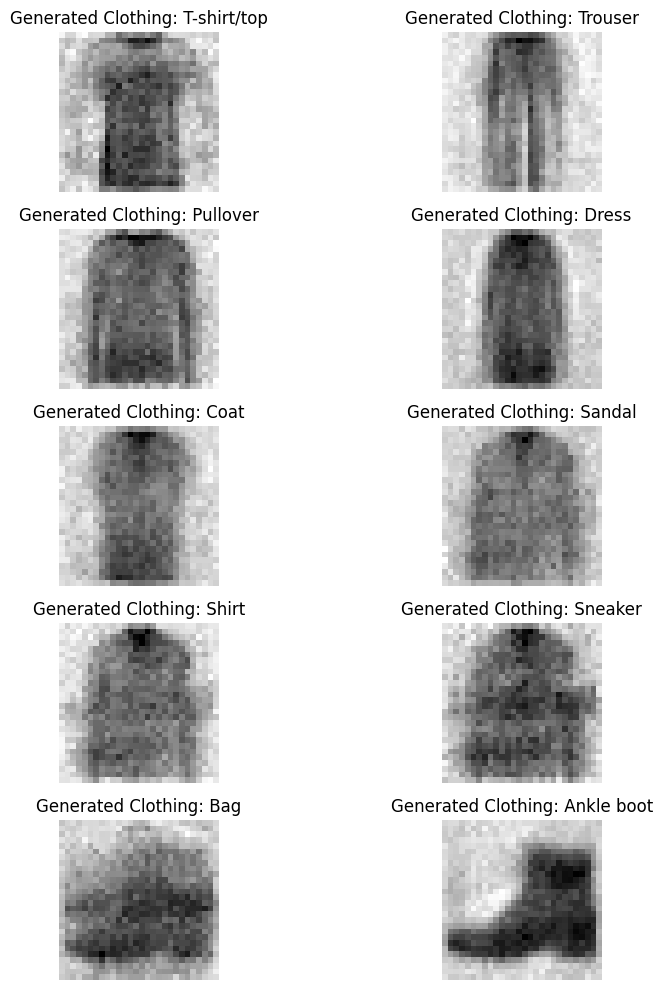

In [19]:
# Visualize a Samples
v0 = torch.randn(N, device=device)
a_all, b_all, W_all = model(label_inputs)

fig, axes = plt.subplots(5, 2, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    v_sample = Block_Gibbs_sampling(v0, W_all[i], a_all[i], b_all[i], 1000)
    ax.imshow(1 - recover(v_sample.cpu().reshape(28, 28), mean, std), cmap="gray")
    ax.set_title(f"Generated Clothing: {class_names[i]}")
    ax.axis("off")

plt.tight_layout()
plt.show()